# Boberg–Lantz cyclic steam stimulation — Example 8.6

**Self-contained scientific notebook** reproducing the cyclic steam-stimulation calculation in Green & Willhite, *Enhanced Oil Recovery*, 2nd ed., Example 8.6 (pp. 538–542).

## 1. Physical workflow

Steam injection heats the near-wellbore region; oil viscosity decreases and productivity increases. During production the heated zone cools because of conduction and produced-fluid heat removal. The calculation uses:

1. Marx–Langenheim heated-zone geometry.
2. Boberg–Lantz dimensionless radial and vertical cooling approximations.
3. Temperature-dependent oil density and viscosity.
4. Productivity ratio, water–oil ratio and cumulative produced-fluid heat removal.


In [29]:
from dataclasses import dataclass, asdict
from typing import Iterable
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Open the notebook from either the repository root or its notebooks/ directory.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

OUTPUTS = ROOT / "notebook_outputs"
OUTPUTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.25})

## 2. Textbook inputs

The values below are the defaults in `ModelInputs`, preserved from the repository's Example 8.6 implementation. They use **ft, °F, Btu, days, STB/D**, and the other field units specified by the model.

In [30]:
@dataclass(frozen=True)
class ModelInputs:
    """Green & Willhite Example 8.6 inputs (field units)."""
    h: float = 41.0
    T_s: float = 381.82
    T_r: float = 93.0
    Ms: float = 41.0
    Mr: float = 38.5
    api: float = 13.5
    mu_oc: float = 2026.0
    B_oc: float = 1.01
    r_e: float = 233.5
    r_w: float = 0.292
    W_is: float = 1000.0
    t_inj: float = 14.0
    fsd: float = 0.7
    alpha: float = 0.731
    H_wT: float = 355.4
    L_vdh: float = 843.3
    H_wr: float = 61.0
    qoi: float = 5.79
    Pres: float = 125.0
    BHP: float = 25.0
    a: float = 16.1368
    b: float = 5.6934
    beta: float = 3.5e-4
    Fwoc: float = 0.25
    C_w: float = 1.016
    rho_w: float = 54.4
    C_o: float = 0.5

DEFAULT_TIMESTEPS = (4, 60, 90, 120, 150, 180, 210, 240, 260,
                     290, 320, 350, 380, 410, 440, 470, 500, 530)


inputs = ModelInputs()
display(pd.DataFrame([(k,v) for k,v in asdict(inputs).items()], columns=["Parameter", "Value"]))

,Parameter,Value
0,h,41.00000
1,T_s,381.82000
2,T_r,93.00000
3,Ms,41.00000
4,Mr,38.50000
5,api,13.50000
6,mu_oc,2026.00000
7,B_oc,1.01000
8,r_e,233.50000
9,r_w,0.29200


## 3. Equations and original calculation functions

The **Marx–Langenheim** heated-zone calculation begins with

$$H_s=H_{wT}+f_{sd}L_{vdh}-H_{wr},\qquad t_D=\frac{4\alpha t_{inj}}{h^2}.$$

The heated radius is $r_h=\sqrt{A_h/\pi}$. The production loop includes dimensionless radial and vertical cooling, an ASTM-type temperature–viscosity correlation, hot-to-cold productivity enhancement, water–oil ratio evolution and produced-fluid heat removal.

The functions below preserve the existing repository's numerical formulation and interval-update sequence. The radial cooling expression is a **truncated approximation**; the textbook uses graphical interpolation, and time intervals can affect the production trajectory.

In [31]:
def calculate_initial_oil_density(api: float) -> float:
    return 141.5 / (api + 131.5)

def calculate_oil_density(rho_oi: float, T: float, beta: float = 3.5e-4) -> float:
    return rho_oi * math.exp(-beta * (T - 60.0))

def calculate_oil_viscosity(rho_o: float, T: float, a: float = 16.1368,
                            b: float = 5.6934) -> float:
    lhs = a - b * math.log10(T + 460.0)
    return rho_o * (10.0 ** (10.0 ** lhs) - 0.6)

def G(tD: float) -> float:
    """Marx–Langenheim heat function."""
    if tD < 0.0:
        raise ValueError("tD must be non-negative")
    return math.exp(tD) * math.erfc(math.sqrt(tD)) + 2.0 * math.sqrt(tD / math.pi) - 1.0

def calculate_TDr(tDr: float) -> float:
    """Truncated radial cooling approximation; limited-range approximation."""
    if tDr <= 0.0:
        raise ValueError("tDr must be positive")
    return 1.0 - math.sqrt(tDr / math.pi) * (
        2.0 - tDr / 2.0 - 3.0 * tDr**2 / 16.0
        - 15.0 * tDr**3 / 64.0 - 525.0 * tDr**4 / 1024.0)

def calculate_TDz(tDz: float) -> float:
    if tDz <= 0.0:
        raise ValueError("tDz must be positive")
    return (math.erf(1.0 / math.sqrt(tDz))
            - math.sqrt(tDz / math.pi) * (1.0 - math.exp(-1.0 / tDz)))

def calculate_Fwo(Wp: float, W_is_total: float, Fwoc: float = 0.25) -> float:
    if W_is_total <= 0.0:
        raise ValueError("W_is_total must be positive")
    return Fwoc + 1.83 * math.exp(-7.38 * (Wp / W_is_total))

def calculate_geometry(inputs: ModelInputs) -> dict:
    M = (inputs.Ms + inputs.Mr) / 2.0
    H_s = inputs.H_wT + inputs.fsd * inputs.L_vdh - inputs.H_wr
    tD = 4.0 * inputs.alpha * inputs.t_inj / inputs.h**2
    G_tD = G(tD)
    m_s_rate = inputs.W_is * 5.615 * 62.4
    A_h = ((m_s_rate * H_s * inputs.h) /
           (4.0 * (inputs.T_s - inputs.T_r) * inputs.alpha * M) * G_tD)
    r_h = math.sqrt(A_h / math.pi)
    z = ((m_s_rate * H_s * inputs.t_inj) /
         (math.pi * r_h**2 * (inputs.T_s - inputs.T_r) * M) - inputs.h)
    return dict(M=M, H_s=H_s, tD_injection=tD, G_tD=G_tD,
                m_s_rate=m_s_rate, A_h=A_h, r_h=r_h, z=z)

def calculate_dimensionless_times(t: float, ti: float, alpha: float,
                                  r_h: float, h: float, z: float):
    elapsed = t - ti
    if elapsed <= 0.0:
        raise ValueError("t - ti must be positive")
    return alpha * elapsed / r_h**2, alpha * elapsed / (((h + z) / 2.0)**2)

def run_model(inputs: ModelInputs = ModelInputs(),
              timesteps: Iterable[float] = DEFAULT_TIMESTEPS):
    """Reproduce the interval-based production workflow in the original repository."""
    timesteps = list(timesteps)
    if len(timesteps) < 2:
        raise ValueError("At least two timesteps are required")
    if any(t2 <= t1 for t1, t2 in zip(timesteps[:-1], timesteps[1:])):
        raise ValueError("Timesteps must be strictly increasing")
    geometry = calculate_geometry(inputs)
    H_s = geometry["H_s"]
    m_s_rate = geometry["m_s_rate"]
    r_h = geometry["r_h"]
    z = geometry["z"]
    delta_N_p_o = 0.0
    delta_N_p_w = 0.0
    Wp = 0.0
    Np = 0.0
    CumQ_pi = 0.0
    deltaP = inputs.Pres - inputs.BHP
    Jc = inputs.qoi / deltaP
    delta = 0.0
    T_p = inputs.T_s
    T_Dp = 1.0
    rows = []
    for i, timestep in enumerate(timesteps):
        if i == 0:
            T_D = 1.0
            T_Dp = T_D
            T_p = inputs.T_s
            tD_r = np.nan
            TD_r = np.nan
            tD_z = np.nan
            TD_z = np.nan
        else:
            Np += delta_N_p_o
            Wp += delta_N_p_w
            T_p = inputs.T_r + (inputs.T_s - inputs.T_r) * T_Dp
        F_wo = calculate_Fwo(Wp, inputs.W_is * inputs.t_inj, inputs.Fwoc)
        rho_o_i = calculate_initial_oil_density(inputs.api)
        rho_o = calculate_oil_density(rho_o_i, T_p, inputs.beta)
        mu_oh = calculate_oil_viscosity(rho_o, T_p, inputs.a, inputs.b)
        B_oh = (rho_o_i / rho_o) * inputs.B_oc
        J = ((inputs.B_oc / B_oh) * np.log(inputs.r_e / inputs.r_w) /
             ((mu_oh / inputs.mu_oc) * np.log(r_h / inputs.r_w)
              + np.log(inputs.r_e / r_h)))
        q_oh = J * Jc * deltaP * B_oh
        q_o = q_oh / B_oh
        Q_pi = (5.615 * q_oh *
                (rho_o * 62.4 * inputs.C_o + F_wo * inputs.rho_w * inputs.C_w)
                * (T_p - inputs.T_r))
        if i < len(timesteps) - 1:
            delta_t = timesteps[i + 1] - timestep
        else:
            delta_t = timesteps[i] - timesteps[i - 1]
        CumQ_pi += Q_pi * delta_t
        delta = CumQ_pi / (2.0 * m_s_rate * H_s * inputs.t_inj)
        delta_N_p_o = q_o * delta_t
        delta_N_p_w = delta_N_p_o * F_wo
        if i == 0:
            T_Dp = T_D * (1.0 - delta) - delta
        else:
            tD_r, tD_z = calculate_dimensionless_times(
                timestep, 0.0, inputs.alpha, r_h, inputs.h, z)
            TD_r = calculate_TDr(tD_r)
            TD_z = calculate_TDz(tD_z)
            T_D = TD_r * TD_z
            T_Dp = T_D * (1.0 - delta) - delta
        rows.append({
            "t - ti (days)": timestep, "Tp (F)": T_p, "mu_oh (cp)": mu_oh,
            "qo (STB/D)": q_o, "qoh (RB/D)": q_oh,
            "Fwo (bbl/bbl)": F_wo, "Qpi (Btu/D)": Q_pi,
            "CumQpi (Btu)": CumQ_pi, "delta": delta,
            "tDr": tD_r, "TDr": TD_r, "tDz": tD_z, "TDz": TD_z,
            "TD": T_D, "TDp": T_Dp,
            "dNp (bbl)": delta_N_p_o, "dWp (bbl)": delta_N_p_w,
            "Wp begin (bbl)": Wp, "Np begin (bbl)": Np,
        })
    return pd.DataFrame(rows), geometry


In [32]:
geom = calculate_geometry(inputs)
geometry_units = {"M": "Btu/(ft³·°F)", "H_s": "Btu/lbm", "tD_injection": "–", "G_tD": "–", "m_s_rate": "lbm/day", "A_h": "ft²", "r_h": "ft", "z": "ft"}
display(pd.DataFrame([{"Quantity": k, "Value": v, "Unit": geometry_units.get(k, "")} for k,v in geom.items()]).round(5))

,Quantity,Value,Unit
0,M,39.75000,Btu/(ft³·°F)
1,H_s,884.71000,Btu/lbm
2,tD_injection,0.02435,–
3,G_tD,0.02176,–
4,m_s_rate,350376.00000,lbm/day
5,A_h,8239.92327,ft²
6,r_h,51.21376,ft
7,z,4.87497,ft


## 4. Cooling, viscosity and oil productivity

The dimensional oil temperature is related to the corrected dimensionless temperature by

$$T_p=T_r+(T_s-T_r)T_{Dp}.$$

The model uses an ASTM-type viscosity correlation and a heated-to-cold productivity ratio $J_h/J_c$; the corresponding expressions are implemented in the functions above.

**Caveat:** the source implementation evaluates a truncated analytical approximation for radial cooling. The original worked example used graphical readings, so small discrepancies are expected. The code's first production point assumes $T_D=1$.

In [33]:
results, geom = run_model(inputs, timesteps=DEFAULT_TIMESTEPS)
key_columns = ["t - ti (days)", "Tp (F)", "mu_oh (cp)", "qo (STB/D)", "qoh (RB/D)", "Fwo (bbl/bbl)", "delta"]
display(results[key_columns].round(4))

,t - ti (days),Tp (F),mu_oh (cp),qo (STB/D),qoh (RB/D),Fwo (bbl/bbl),delta
0,4,381.8200,1.2312,22.7445,25.7108,2.0800,0.0382
1,60,359.7278,1.4548,22.9124,25.7011,0.7028,0.0471
2,90,276.3250,3.5055,23.5103,25.6131,0.6010,0.0527
3,120,257.9207,4.5935,23.6193,25.5666,0.5307,0.0574
4,150,243.0911,5.8785,23.6914,25.5119,0.4802,0.0615
5,180,230.5896,7.4098,23.7348,25.4470,0.4423,0.0651
6,210,219.7729,9.2367,23.7528,25.3701,0.4129,0.0683
7,240,210.2557,11.4113,23.7465,25.2791,0.3895,0.0702
8,260,202.1965,13.8458,23.7184,25.1780,0.3765,0.0729
9,290,196.6606,15.9456,23.6827,25.0914,0.3599,0.0754


## 5. Production response and thermal evolution


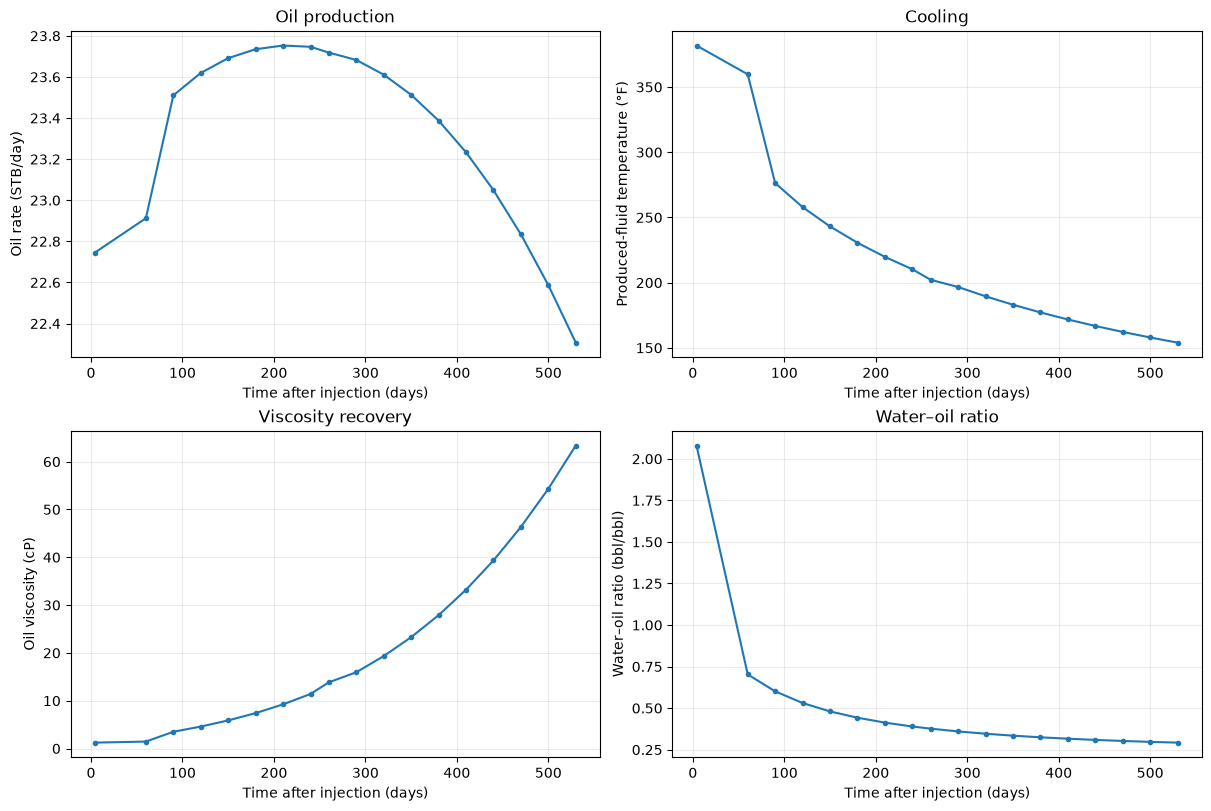

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
series = [
    ("qo (STB/D)", "Oil rate (STB/day)", "Oil production"),
    ("Tp (F)", "Produced-fluid temperature (°F)", "Cooling"),
    ("mu_oh (cp)", "Oil viscosity (cP)", "Viscosity recovery"),
    ("Fwo (bbl/bbl)", "Water–oil ratio (bbl/bbl)", "Water–oil ratio"),
]
for ax, (field, ylabel, title) in zip(axes.flat, series):
    ax.plot(results["t - ti (days)"], results[field], marker="o", ms=3)
    ax.set(xlabel="Time after injection (days)", ylabel=ylabel, title=title)
fig.savefig(OUTPUTS / "steam_stimulation_overview.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Compare with published Example 8.6 checkpoints

The repository includes selected textbook/reference checkpoints in `validation/selected_benchmarks.csv`. They cover the injection geometry and **first production interval**. This is a targeted check, not validation of the full 530-day curve.

Small differences may reflect rounding and replacement of textbook graphical readings by analytical approximations.

In [35]:
bench = pd.read_csv(ROOT / "validation" / "selected_benchmarks.csv")
first = results.iloc[0]
computed = {
    "Steam heat, Hs": geom["H_s"],
    "Heated radius, rh": geom["r_h"],
    "Hot-oil FVF, Boh": first["qoh (RB/D)"] / first["qo (STB/D)"],
    "Hot-oil viscosity": first["mu_oh (cp)"],
    "Surface oil rate, qo": first["qo (STB/D)"],
    "Reservoir oil rate, qoh": first["qoh (RB/D)"],
    "Heat-removal fraction, delta": first["delta"],
}
bench["model_value"] = bench["quantity"].map(computed)
bench["difference"] = bench["model_value"] - bench["reference_value"]
bench["relative_error_pct"] = 100 * bench["difference"] / bench["reference_value"]
display(bench.round(5))
bench.to_csv(OUTPUTS / "selected_benchmark_comparison.csv", index=False)

,quantity,reference_value,unit,note,model_value,difference,relative_error_pct
0,"Steam heat, Hs",884.700,Btu/lbm,Worked example,884.71000,0.01000,0.00113
1,"Heated radius, rh",51.200,ft,Worked example,51.21376,0.01376,0.02687
2,"Hot-oil FVF, Boh",1.130,RB/STB,First production interval,1.13042,0.00042,0.03698
3,Hot-oil viscosity,1.220,cp,First production interval,1.23118,0.01118,0.91614
4,"Surface oil rate, qo",22.750,STB/D,Hand calculation,22.74448,-0.00552,-0.02425
5,"Reservoir oil rate, qoh",25.710,RB/D,Hand calculation,25.71077,0.00077,0.00299
6,"Heat-removal fraction, delta",0.038,-,First production interval,0.03825,0.00025,0.64654


## 7. Time-interval sensitivity — diagnostic

The original calculation uses irregular production intervals and an interval-based heat-removal approximation. This optional diagnostic uses a denser schedule **while preserving the same initial time (day 4)**. Differences are indicators of numerical sensitivity, not automatically errors. The finer run must not be used to claim textbook agreement at the same discretization.

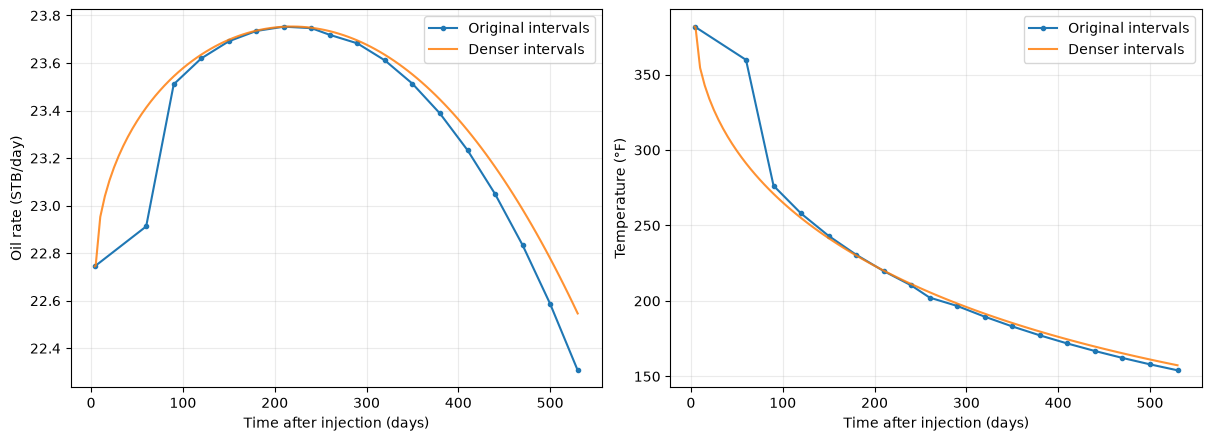

In [36]:
dense_times = np.unique(np.r_[4.0, np.arange(5.0, 531.0, 5.0), np.asarray(DEFAULT_TIMESTEPS, dtype=float)])
dense, _ = run_model(inputs, timesteps=dense_times)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
for ax, col, ylabel in [(axes[0], "qo (STB/D)", "Oil rate (STB/day)"), (axes[1], "Tp (F)", "Temperature (°F)")]:
    ax.plot(results["t - ti (days)"], results[col], "o-", label="Original intervals", markersize=3)
    ax.plot(dense["t - ti (days)"], dense[col], "-", label="Denser intervals", alpha=0.85)
    ax.set(xlabel="Time after injection (days)", ylabel=ylabel)
    ax.legend()
fig.savefig(OUTPUTS / "timestep_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Save results and limitations

The notebook writes its own outputs to `notebook_outputs/` (ignored by Git), keeping the published example figures and reference data untouched.

**Reference:** Green, D. W. and Willhite, G. P., *Enhanced Oil Recovery*, 2nd ed., Example 8.6, pp. 538–542.

In [37]:
results.to_csv(OUTPUTS / "example_8_6_timeseries.csv", index=False)
print("Saved notebook outputs to:", OUTPUTS.resolve())

Saved notebook outputs to: C:\Python scripts\repos\boberg-lantz-steam-stimulation\notebook_outputs
